# Figure S12A — Correctly scored residues per 100 on CAID3 Disorder-PDB

For each CAID3 disorder predictor, the number of residues labelled correctly (disordered or ordered) per 100 assessed residues of the CAID3 Disorder-PDB reference, top 40 shown. metapredict V1, V2 and V3 are coloured, and the bracket gives the gap between the best predictor and metapredict V3.

**How it is made.** Each method is scored on its own submitted binary calls; raw-score-only methods are thresholded at 0.5 (AlphaFold RSA 0.581, AlphaFold pLDDT 0.312), as in Figure 1C. metapredict V1–V3 are predicted with metapredict 3.1.0 (`data/metapredict_caid/` in the shared data directory) using its default binary calls (residues inside predicted IDRs are disordered).

**Output:** `figures/figure_S12A.pdf`

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from caid_accuracy import score_caid3_field
from figtools import (FIELD_COLOR, VERSION_COLORS, apply_style, require_metapredict_3_1, save_panel,
                      shared_data_path)

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

TOP_N = 40

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
scores = score_caid3_field(str(shared_data_path('caid_references', 'caid3_disorder_pdb.fasta')),
                           str(shared_data_path('caid_references', 'caid3_disorder_pdb_results.csv')))
names = list(scores)[:TOP_N]
values = list(scores.values())[:TOP_N]
x = np.arange(1, len(names) + 1)
print(f'{len(scores)} predictors scored; showing the top {TOP_N}')
for name in ['metapredict V1', 'metapredict V2', 'metapredict V3']:
    print(f'{name}: {scores[name]:.2f} correct per 100 (rank {list(scores).index(name) + 1})')


def draw_bars(ax, heights):
    """Black bars for the field with metapredict versions recoloured."""
    ax.bar(x, heights, color=FIELD_COLOR)
    for version, color in VERSION_COLORS.items():
        name = f'metapredict {version}'
        if name in names:
            ax.bar(names.index(name) + 1, heights[names.index(name)], color=color,
                   linewidth=0.5, edgecolor='black')
    ax.set_xticks(x, names, fontsize=7, rotation=45, horizontalalignment='right',
                  rotation_mode='anchor')
    ax.tick_params(axis='y', labelsize=7)
    ax.set_xlim(0.4, len(names) + 0.6)

66 predictors scored; showing the top 40
metapredict V1: 86.83 correct per 100 (rank 23)
metapredict V2: 89.03 correct per 100 (rank 9)
metapredict V3: 89.65 correct per 100 (rank 7)


Wrote figures/figure_S12A.pdf


PosixPath('figures/figure_S12A.pdf')

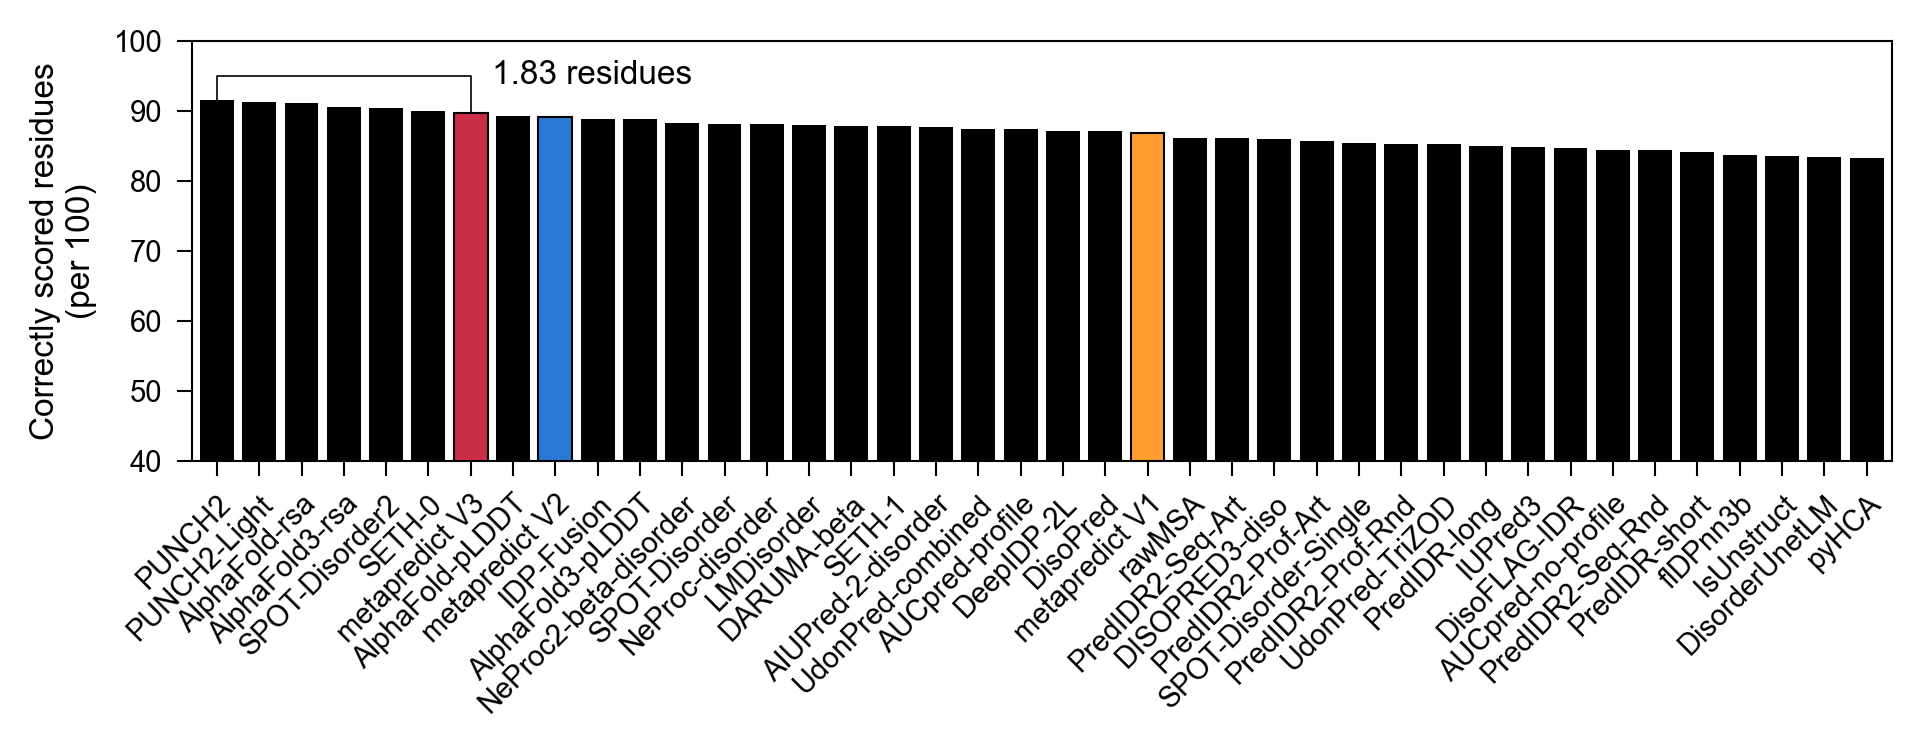

In [3]:
# bracket from the best predictor to metapredict V3
BRACKET_Y = 95
mp_x = names.index('metapredict V3') + 1
gap_to_v3 = values[0] - values[mp_x - 1]

fig, ax = plt.subplots(figsize=(6.5, 2.6), dpi=150)
draw_bars(ax, values)
ax.plot([1, 1, mp_x, mp_x], [values[0], BRACKET_Y, BRACKET_Y, values[mp_x - 1]], '-k', linewidth=0.4)
ax.text(mp_x + 0.5, BRACKET_Y, f'{gap_to_v3:.2f} residues', fontsize=8, va='center')
ax.set_ylim(40, 100)
ax.set_ylabel('Correctly scored residues\n(per 100)', fontsize=8)
plt.tight_layout()
save_panel(fig, 'figure_S12A')